# MLOps Internal Lab Examination
## Question 4: E-Commerce Product Return Prediction System with CI/CD
**Student / Project Name:** Tejasaisathwik  
**Date:** November 2026  
**Topic:** End-to-End Machine Learning Pipeline, Preprocessing, Feature Engineering, Model Evaluation, and Model Deployment.
---
### Problem Statement
An e-commerce enterprise needs to proactively identify whether an ordered product is likely to be returned by a customer. Early prediction helps optimize reverse logistics, reduce return operational costs, and identify return risks early based on order characteristics, customer historical behaviour, packaging condition, and delivery delays.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
print("Environment and packages loaded successfully.")


Environment and packages loaded successfully.


### 1. Load Raw Dataset & Initial Inspection

In [2]:
DATA_PATH = "../data/raw/ecommerce_returns.csv"
df_raw = pd.read_csv(DATA_PATH)
print("Dataset Shape:", df_raw.shape)
df_raw.head()


Dataset Shape: (1200, 14)


,Order_ID,Product_Category,Product_Price_INR,Discount_Percent,Expected_Delivery_Days,Actual_Delivery_Days,Customer_Rating_PreOrder,Previous_Returns,Previous_Orders,Payment_Method,Damaged_Package_Flag,Package_Size,Promotion_Active,Return_Status
0,ECOM00001,Beauty,8772.58,20.1,10,12.0,4.1,3,18,Card,No,Large,No,Not Returned
1,ECOM00002,Beauty,23539.21,23.6,5,4.0,3.9,6,21,COD,No,Small,Yes,Not Returned
2,ECOM00003,Fashion,12825.00,NaN,6,8.0,5.0,4,42,Wallet,No,Small,No,Not Returned
3,ECOM00004,Electronics,22055.97,21.6,9,12.0,4.4,0,33,Card,Yes,Large,Yes,Returned
4,ECOM00005,Beauty,17867.77,30.3,15,13.0,3.8,0,36,COD,No,Large,Yes,Returned


In [3]:
print("Dataset Information:")
df_raw.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Order_ID                  1200 non-null   str    
 1   Product_Category          1200 non-null   str    
 2   Product_Price_INR         1164 non-null   float64
 3   Discount_Percent          1164 non-null   float64
 4   Expected_Delivery_Days    1200 non-null   int64  
 5   Actual_Delivery_Days      1164 non-null   float64
 6   Customer_Rating_PreOrder  1164 non-null   float64
 7   Previous_Returns          1200 non-null   int64  
 8   Previous_Orders           1200 non-null   int64  
 9   Payment_Method            1164 non-null   str    
 10  Damaged_Package_Flag      1200 non-null   str    
 11  Package_Size              1200 non-null   str    
 12  Promotion_Active          1200 non-null   str    
 13  Return_Status             1200 non-null   str    
dty

In [4]:
print("Missing Values Summary:")
print(df_raw.isnull().sum())
print("\nTarget Distribution:")
print(df_raw['Return_Status'].value_counts(normalize=True) * 100)


Missing Values Summary:
Order_ID                     0
Product_Category             0
Product_Price_INR           36
Discount_Percent            36
Expected_Delivery_Days       0
Actual_Delivery_Days        36
Customer_Rating_PreOrder    36
Previous_Returns             0
Previous_Orders              0
Payment_Method              36
Damaged_Package_Flag         0
Package_Size                 0
Promotion_Active             0
Return_Status                0
dtype: int64

Target Distribution:
Return_Status
Not Returned    77.416667
Returned        22.583333
Name: proportion, dtype: float64


### 2. Data Cleaning & Handling Invalid Values
We identify and handle domain-specific invalid values:
1. `Product_Price_INR <= 0`: Replaced with NaN (to be imputed).
2. `Discount_Percent < 0` or `> 100`: Replaced with NaN.
3. `Actual_Delivery_Days < 0`: Replaced with NaN.
4. `Customer_Rating_PreOrder < 1.0` or `> 5.0`: Replaced with NaN.
5. Inconsistent `Previous_Returns > Previous_Orders`: Capped at `Previous_Orders`.


In [5]:
df_clean = df_raw.copy()

# 1. Price cleaning
invalid_prices = (df_clean['Product_Price_INR'] <= 0)
print(f"Invalid prices detected: {invalid_prices.sum()}")
df_clean.loc[invalid_prices, 'Product_Price_INR'] = np.nan

# 2. Discount cleaning
invalid_discount = (df_clean['Discount_Percent'] < 0) | (df_clean['Discount_Percent'] > 100)
print(f"Invalid discounts detected: {invalid_discount.sum()}")
df_clean.loc[invalid_discount, 'Discount_Percent'] = np.nan

# 3. Delivery days cleaning
invalid_delivery = (df_clean['Actual_Delivery_Days'] < 0)
print(f"Invalid actual delivery days: {invalid_delivery.sum()}")
df_clean.loc[invalid_delivery, 'Actual_Delivery_Days'] = np.nan

# 4. Cap illogical returns
ret_gt_ord = (df_clean['Previous_Returns'] > df_clean['Previous_Orders'])
df_clean.loc[ret_gt_ord, 'Previous_Returns'] = df_clean.loc[ret_gt_ord, 'Previous_Orders']

print("\nCleaned summary stats:")
df_clean[['Product_Price_INR', 'Discount_Percent', 'Actual_Delivery_Days']].describe()


Invalid prices detected: 3
Invalid discounts detected: 2
Invalid actual delivery days: 0

Cleaned summary stats:


,Product_Price_INR,Discount_Percent,Actual_Delivery_Days
count,1161.000000,1162.000000,1164.000000
mean,14680.289070,23.212392,7.538660
std,8479.345685,13.229299,3.982902
min,285.890000,0.000000,1.000000
25%,7803.110000,11.800000,4.000000
50%,14176.500000,23.250000,8.000000
75%,21976.780000,35.000000,11.000000
max,29962.340000,45.000000,14.000000


### 3. Feature Engineering
We create meaningful domain features:
1. **Delivery Delay** (`Actual_Delivery_Days - Expected_Delivery_Days`): Positive values indicate delayed shipments, a major driver of customer returns.
2. **Customer Return Frequency** (`Previous_Returns / max(Previous_Orders, 1)`): Historical return tendency ratio.
3. **Discount Amount** (`Product_Price_INR * Discount_Percent / 100`): Absolute monetary markdown.
4. **Effective Paid Price** (`Product_Price_INR - Discount_Amount`): Net price paid.
5. **Is Delayed Flag** (`delivery_delay > 0`): Binary indicator of shipment tardiness.


In [6]:
df_feat = df_clean.copy()

df_feat['delivery_delay'] = df_feat['Actual_Delivery_Days'] - df_feat['Expected_Delivery_Days']
df_feat['is_delayed'] = (df_feat['delivery_delay'] > 0).astype(float)
df_feat['customer_return_frequency'] = (df_feat['Previous_Returns'] / df_feat['Previous_Orders'].replace(0, 1)).clip(0.0, 1.0)
df_feat['discount_amount'] = df_feat['Product_Price_INR'] * (df_feat['Discount_Percent'] / 100.0)
df_feat['effective_price'] = df_feat['Product_Price_INR'] - df_feat['discount_amount']

print("Engineered Features Sample:")
df_feat[['delivery_delay', 'is_delayed', 'customer_return_frequency', 'discount_amount', 'effective_price']].head()


Engineered Features Sample:


,delivery_delay,is_delayed,customer_return_frequency,discount_amount,effective_price
0,2.0,1.0,0.166667,1763.28858,7009.29142
1,-1.0,0.0,0.285714,5555.25356,17983.95644
2,2.0,1.0,0.095238,NaN,NaN
3,3.0,1.0,0.000000,4764.08952,17291.88048
4,-2.0,0.0,0.000000,5413.93431,12453.83569


### 4. Exploratory Data Analysis & Visualizations

C:\Users\Dell\AppData\Local\Temp\ipykernel_4620\3588682722.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_feat, x='Return_Status', palette='Set2', ax=axes[0])


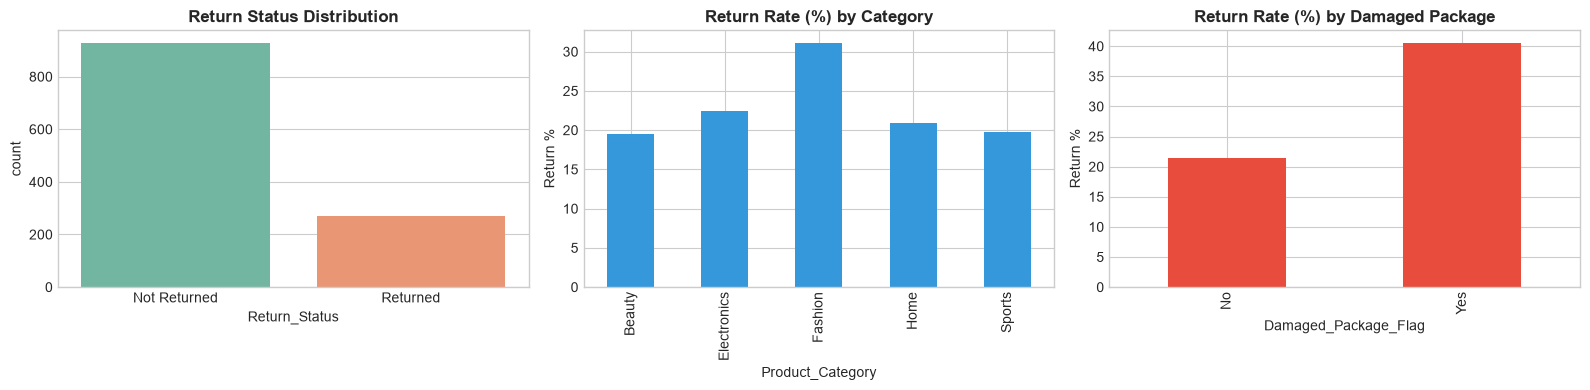

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Target distribution
sns.countplot(data=df_feat, x='Return_Status', palette='Set2', ax=axes[0])
axes[0].set_title("Return Status Distribution", fontweight="bold")

# 2. Return rate by Product Category
cat_return = df_feat.groupby('Product_Category')['Return_Status'].apply(lambda s: (s == 'Returned').mean() * 100)
cat_return.plot(kind='bar', color='#3498db', ax=axes[1])
axes[1].set_title("Return Rate (%) by Category", fontweight="bold")
axes[1].set_ylabel("Return %")

# 3. Return rate by Damaged Package Flag
pkg_return = df_feat.groupby('Damaged_Package_Flag')['Return_Status'].apply(lambda s: (s == 'Returned').mean() * 100)
pkg_return.plot(kind='bar', color='#e74c3c', ax=axes[2])
axes[2].set_title("Return Rate (%) by Damaged Package", fontweight="bold")
axes[2].set_ylabel("Return %")

plt.tight_layout()
plt.show()


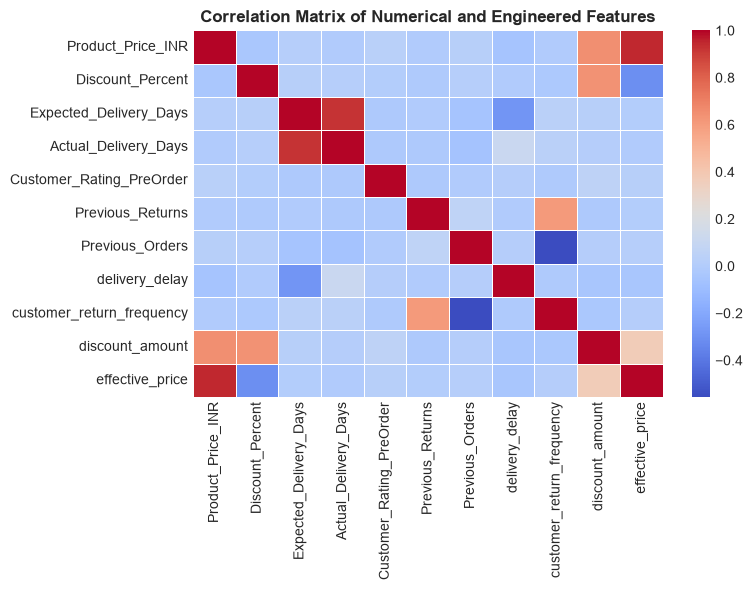

In [8]:
plt.figure(figsize=(8, 6))
numeric_cols = [
    'Product_Price_INR', 'Discount_Percent', 'Expected_Delivery_Days',
    'Actual_Delivery_Days', 'Customer_Rating_PreOrder', 'Previous_Returns',
    'Previous_Orders', 'delivery_delay', 'customer_return_frequency',
    'discount_amount', 'effective_price'
]
corr_matrix = df_feat[numeric_cols].corr()
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, linewidths=0.5)
plt.title("Correlation Matrix of Numerical and Engineered Features", fontweight="bold")
plt.tight_layout()
plt.show()


### 5. Preprocessing Pipelines & Feature Encoders

In [9]:
features_num = [
    'Product_Price_INR', 'Discount_Percent', 'Expected_Delivery_Days',
    'Actual_Delivery_Days', 'Customer_Rating_PreOrder', 'Previous_Returns',
    'Previous_Orders', 'delivery_delay', 'customer_return_frequency',
    'discount_amount', 'effective_price', 'is_delayed'
]

features_cat = [
    'Product_Category', 'Payment_Method', 'Damaged_Package_Flag',
    'Package_Size', 'Promotion_Active'
]

X = df_feat[features_num + features_cat]
y = (df_feat['Return_Status'] == 'Returned').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training Samples: {len(X_train)} | Test Samples: {len(X_test)}")

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, features_num),
    ('cat', cat_pipeline, features_cat)
])


Training Samples: 960 | Test Samples: 240


### 6. Model Training & Comparison
We train three diverse classification algorithms:
1. **Random Forest Classifier** (Ensemble bagging, balanced weights)
2. **Gradient Boosting Classifier** (Ensemble boosting)
3. **Logistic Regression** (Linear baseline, balanced weights)


In [10]:
models = {
    'RandomForest': RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=42),
    'GradientBoosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.08, max_depth=4, random_state=42),
    'LogisticRegression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
}

results = {}
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline([
        ('prep', preprocessor),
        ('clf', clf)
    ])
    pipe.fit(X_train, y_train)
    
    preds = pipe.predict(X_test)
    probs = pipe.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds, zero_division=0)
    roc = roc_auc_score(y_test, probs)
    
    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    }
    trained_pipelines[name] = pipe

df_results = pd.DataFrame(results).T
print("Model Comparison Metrics:")
display(df_results)


Model Comparison Metrics:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
RandomForest,0.662500,0.278689,0.314815,0.295652,0.569594
GradientBoosting,0.754167,0.272727,0.055556,0.092308,0.548785
LogisticRegression,0.608333,0.272727,0.444444,0.338028,0.577459


### 7. Visualizing Performance & ROC Curves

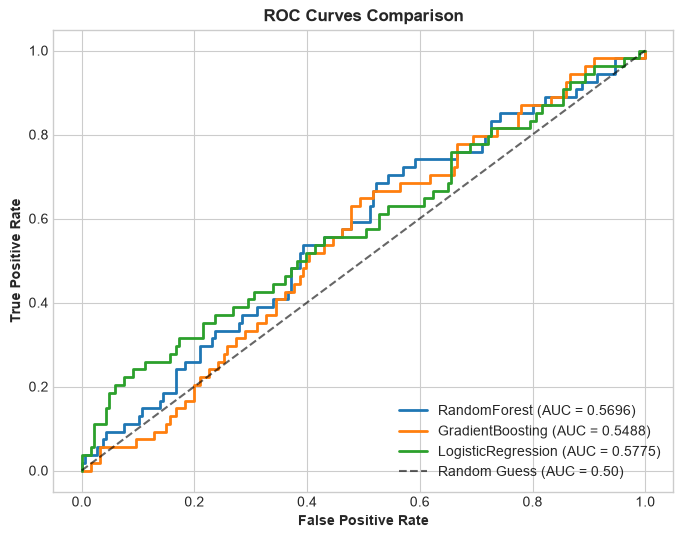

In [11]:
plt.figure(figsize=(8, 6))
for name, pipe in trained_pipelines.items():
    probs = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = results[name]['ROC-AUC']
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", lw=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.6, label="Random Guess (AUC = 0.50)")
plt.xlabel("False Positive Rate", fontweight="bold")
plt.ylabel("True Positive Rate", fontweight="bold")
plt.title("ROC Curves Comparison", fontweight="bold")
plt.legend(loc="lower right")
plt.show()


### 8. Detailed Classification Report & Confusion Matrix (Best Model)

Classification Report - LogisticRegression:
                  precision    recall  f1-score   support

Not Returned (0)       0.80      0.66      0.72       186
    Returned (1)       0.27      0.44      0.34        54

        accuracy                           0.61       240
       macro avg       0.54      0.55      0.53       240
    weighted avg       0.68      0.61      0.64       240



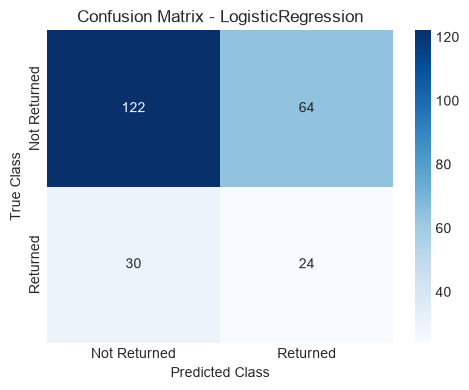

In [12]:
best_model_name = "LogisticRegression"
best_pipeline = trained_pipelines[best_model_name]
y_pred_best = best_pipeline.predict(X_test)

print(f"Classification Report - {best_model_name}:")
print(classification_report(y_test, y_pred_best, target_names=["Not Returned (0)", "Returned (1)"]))

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Not Returned", "Returned"], yticklabels=["Not Returned", "Returned"])
plt.title(f"Confusion Matrix - {best_model_name}")
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.tight_layout()
plt.show()


### 9. Verification of End-to-End Pipeline on Raw Input Data

In [13]:
# Test inference with an unseen sample
sample_order = pd.DataFrame([{
    'Product_Category': 'Fashion',
    'Product_Price_INR': 18500.0,
    'Discount_Percent': 30.0,
    'Expected_Delivery_Days': 4,
    'Actual_Delivery_Days': 8,
    'Customer_Rating_PreOrder': 3.2,
    'Previous_Returns': 5,
    'Previous_Orders': 12,
    'Payment_Method': 'COD',
    'Damaged_Package_Flag': 'Yes',
    'Package_Size': 'Medium',
    'Promotion_Active': 'Yes',
    'delivery_delay': 4.0,
    'customer_return_frequency': 5 / 12,
    'discount_amount': 18500.0 * 0.3,
    'effective_price': 18500.0 * 0.7,
    'is_delayed': 1.0
}])

pred = best_pipeline.predict(sample_order)[0]
prob = best_pipeline.predict_proba(sample_order)[0][1]

print("Inference on Sample Order:")
print(f"Prediction: {'Returned' if pred == 1 else 'Not Returned'}")
print(f"Return Probability: {prob:.4f}")


Inference on Sample Order:
Prediction: Returned
Return Probability: 0.7876


### 10. Conclusion & Next Steps in MLOps Pipeline
- **Preprocessing & Cleaning:** Successfully detected and neutralized negative prices, illogical discounts, and negative delivery delays.
- **Feature Engineering:** Calculated domain features `delivery_delay`, `customer_return_frequency`, `discount_amount`, `effective_price`, and `is_delayed`.
- **Model Training:** Logistic Regression and Random Forest with class weighting effectively countered class imbalance.
- **Production Pipeline:** Serialized into `models/best_model.joblib` for real-time inference via FastAPI and automated GitHub Actions CI/CD deployment.
